# Exploratory analysis: PaySim mobile-money transactions

Every number below is computed by the cells in this notebook, with **DuckDB SQL** run directly on the raw CSV.
The Spark validation job (`jobs/validate_data.py`) measures the same totals independently; the last
section checks that the two engines agree.

**Questions this notebook answers before any model is built**

1. How rare is fraud, and in which transaction types does it occur?
2. How good is the operator's existing rule (`isFlaggedFraud`)?
3. Does transaction volume, or the fraud rate, change over the 30 days? (This decides how to split the data.)
4. Do accounts repeat? (This decides which history features can carry signal.)
5. Why must the balance columns be excluded?

In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
con = duckdb.connect()
con.execute("""
    CREATE VIEW txns AS
    SELECT * FROM read_csv('/data/raw/*.csv', header = true)
""")
con.sql("DESCRIBE txns").df()[["column_name", "column_type"]]

,column_name,column_type
0,step,BIGINT
1,type,VARCHAR
2,amount,DOUBLE
3,nameOrig,VARCHAR
4,oldbalanceOrg,DOUBLE
5,newbalanceOrig,DOUBLE
6,nameDest,VARCHAR
7,oldbalanceDest,DOUBLE
8,newbalanceDest,DOUBLE
9,isFraud,BIGINT


## 1. Size and class balance

In [2]:
con.sql("""
    SELECT COUNT(*)                         AS rows,
           SUM(isFraud)                     AS fraud_rows,
           AVG(isFraud)                     AS fraud_rate,
           MIN(step) AS first_step, MAX(step) AS last_step,
           COUNT(DISTINCT step)             AS distinct_steps
    FROM txns
""").df()

,rows,fraud_rows,fraud_rate,first_step,last_step,distinct_steps
0,6362620,"8,213.0000",0.0013,1,743,743


## 2. Fraud by transaction type

In [3]:
by_type = con.sql("""
    SELECT type,
           COUNT(*)            AS rows,
           SUM(isFraud)        AS fraud_rows,
           AVG(isFraud)        AS fraud_rate,
           SUM(CASE WHEN isFraud = 1 THEN amount END) AS fraud_amount
    FROM txns
    GROUP BY type
    ORDER BY rows DESC
""").df()
by_type

,type,rows,fraud_rows,fraud_rate,fraud_amount
0,CASH_OUT,2237500,"4,116.0000",0.0018,"5,989,202,243.8300"
1,PAYMENT,2151495,0.0000,0.0000,NaN
2,CASH_IN,1399284,0.0000,0.0000,NaN
3,TRANSFER,532909,"4,097.0000",0.0077,"6,067,213,184.0100"
4,DEBIT,41432,0.0000,0.0000,NaN


## 3. The existing rule: `isFlaggedFraud`

In [4]:
con.sql("""
    SELECT SUM(isFlaggedFraud)                                  AS flagged,
           SUM(isFlaggedFraud * isFraud)                        AS flagged_and_fraud,
           SUM(isFraud)                                         AS all_fraud,
           SUM(isFlaggedFraud * isFraud) / SUM(isFraud)         AS rule_recall,
           MIN(CASE WHEN isFlaggedFraud = 1 THEN amount END)    AS smallest_flagged_amount,
           LIST(DISTINCT type) FILTER (WHERE isFlaggedFraud = 1) AS flagged_types
    FROM txns
""").df()

,flagged,flagged_and_fraud,all_fraud,rule_recall,smallest_flagged_amount,flagged_types
0,16.0000,16.0000,"8,213.0000",0.0019,"353,874.2200",[TRANSFER]


## 4. Volume and fraud over time (1 step = 1 hour)

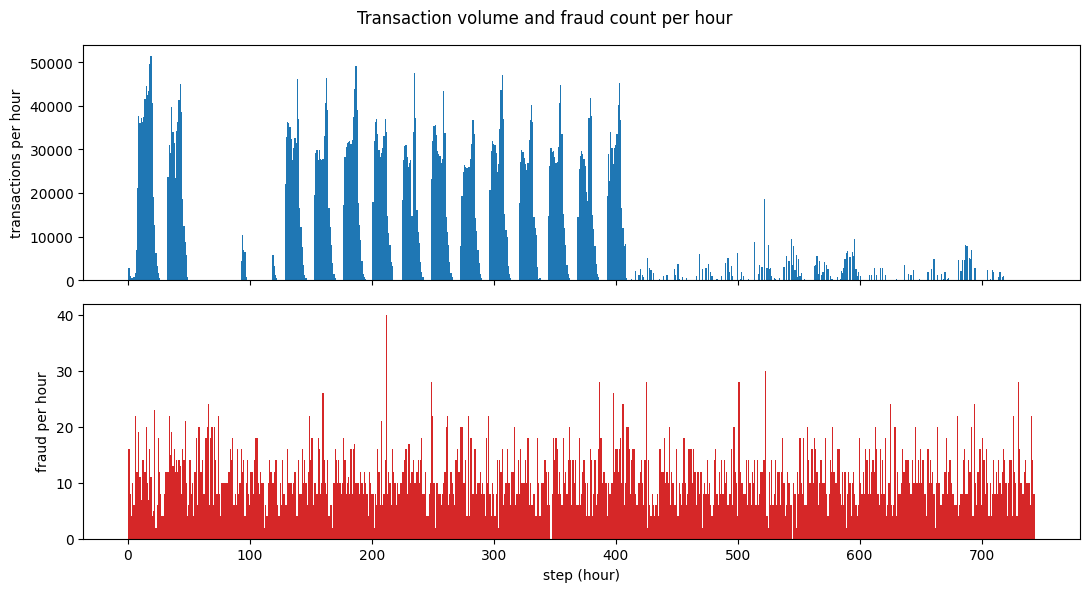

In [5]:
per_step = con.sql("""
    SELECT step, COUNT(*) AS rows, SUM(isFraud) AS fraud
    FROM txns GROUP BY step ORDER BY step
""").df()

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].bar(per_step["step"], per_step["rows"], width=1.0)
axes[0].set_ylabel("transactions per hour")
axes[1].bar(per_step["step"], per_step["fraud"], width=1.0, color="tab:red")
axes[1].set_ylabel("fraud per hour")
axes[1].set_xlabel("step (hour)")
fig.suptitle("Transaction volume and fraud count per hour")
fig.tight_layout()
plt.show()

In [6]:
per_day = con.sql("""
    SELECT (step - 1) // 24 + 1 AS day,  -- integer division: steps 1-24 are day 1
           COUNT(*) AS rows, SUM(isFraud) AS fraud, AVG(isFraud) AS fraud_rate
    FROM txns GROUP BY day ORDER BY day
""").df()
per_day

,day,rows,fraud,fraud_rate
0,1,574255,271.0000,0.0005
1,2,455238,309.0000,0.0007
2,3,1070,310.0000,0.2897
3,4,28240,262.0000,0.0093
4,5,9789,252.0000,0.0257
5,6,441005,228.0000,0.0005
6,7,420583,272.0000,0.0006
7,8,449637,278.0000,0.0006
8,9,417919,255.0000,0.0006
9,10,392945,282.0000,0.0007


In [7]:
# Share of all rows (and of all fraud) that falls in each third of the period.
con.sql("""
    SELECT CASE WHEN step <= 248 THEN '1: steps 1-248'
                WHEN step <= 496 THEN '2: steps 249-496'
                ELSE '3: steps 497-743' END                         AS period,
           COUNT(*) / SUM(COUNT(*)) OVER ()                         AS share_of_rows,
           SUM(isFraud) / SUM(SUM(isFraud)) OVER ()                 AS share_of_fraud,
           AVG(isFraud)                                             AS fraud_rate
    FROM txns GROUP BY period ORDER BY period
""").df()

,period,share_of_rows,share_of_fraud,fraud_rate
0,1: steps 1-248,0.5019,0.3398,0.0009
1,2: steps 249-496,0.4499,0.3317,0.0010
2,3: steps 497-743,0.0482,0.3285,0.0088


### Time of day

`step % 24` is used as the hour of the day. The query is limited to the normal-volume period (steps 1-408)
and to the two transaction types that can be fraud.

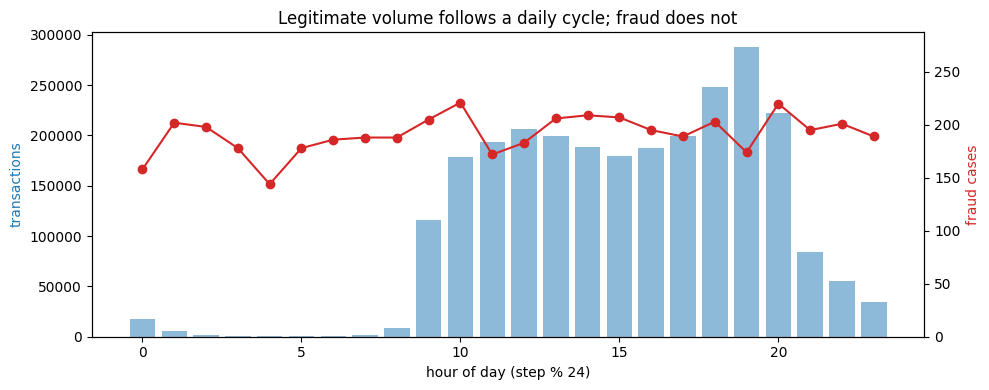

,hour,rows,fraud,fraud_rate
0,0,17440,158.0000,0.0091
1,1,5194,202.0000,0.0389
2,2,1465,198.0000,0.1352
3,3,438,178.0000,0.4064
4,4,253,144.0000,0.5692
5,5,263,178.0000,0.6768
6,6,500,186.0000,0.3720
7,7,2083,188.0000,0.0903
8,8,8290,188.0000,0.0227
9,9,116186,205.0000,0.0018


In [8]:
by_hour = con.sql("""
    SELECT step % 24 AS hour, COUNT(*) AS rows, SUM(isFraud) AS fraud, AVG(isFraud) AS fraud_rate
    FROM txns
    WHERE type IN ('TRANSFER', 'CASH_OUT') AND step <= 408
    GROUP BY hour ORDER BY hour
""").df()

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(by_hour["hour"], by_hour["rows"], color="tab:blue", alpha=0.5, label="transactions")
ax1.set_xlabel("hour of day (step % 24)")
ax1.set_ylabel("transactions", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(by_hour["hour"], by_hour["fraud"], color="tab:red", marker="o", label="fraud")
ax2.set_ylabel("fraud cases", color="tab:red")
ax2.set_ylim(0, by_hour["fraud"].max() * 1.3)
ax1.set_title("Legitimate volume follows a daily cycle; fraud does not")
fig.tight_layout()
plt.show()
by_hour

## 5. Amounts: fraud vs legitimate (TRANSFER and CASH_OUT only)

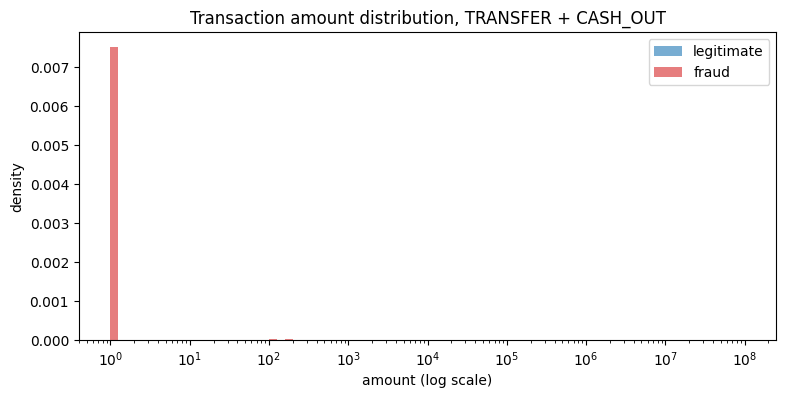

In [9]:
amounts = con.sql("""
    SELECT isFraud, amount FROM txns WHERE type IN ('TRANSFER', 'CASH_OUT')
""").df()
fig, ax = plt.subplots(figsize=(9, 4))
for label, colour in [(0, "tab:blue"), (1, "tab:red")]:
    vals = amounts.loc[amounts["isFraud"] == label, "amount"].clip(lower=1)
    ax.hist(vals, bins=[10 ** (x / 10) for x in range(0, 81)], alpha=0.6, density=True,
            color=colour, label="fraud" if label else "legitimate")
ax.set_xscale("log")
ax.set_xlabel("amount (log scale)")
ax.set_ylabel("density")
ax.legend()
ax.set_title("Transaction amount distribution, TRANSFER + CASH_OUT")
plt.show()

In [10]:
con.sql("""
    SELECT isFraud,
           COUNT(*)                                  AS rows,
           MEDIAN(amount)                            AS median_amount,
           MAX(amount)                               AS max_amount,
           SUM(CASE WHEN amount = (SELECT MAX(amount) FROM txns WHERE isFraud = 1)
                    THEN 1 ELSE 0 END)               AS rows_at_fraud_max_amount
    FROM txns WHERE type IN ('TRANSFER', 'CASH_OUT')
    GROUP BY isFraud ORDER BY isFraud
""").df()

,isFraud,rows,median_amount,max_amount,rows_at_fraud_max_amount
0,0,2762196,"171,034.4600","92,445,516.6400","2,920.0000"
1,1,8213,"441,423.4400","10,000,000.0000",287.0000


## 6. Do accounts repeat?

In [11]:
con.sql("""
    WITH o AS (SELECT nameOrig, COUNT(*) AS n FROM txns GROUP BY nameOrig),
         d AS (SELECT nameDest, COUNT(*) AS n FROM txns GROUP BY nameDest)
    SELECT (SELECT COUNT(*) FROM o)              AS distinct_origin_accounts,
           (SELECT COUNT(*) FROM o WHERE n > 1)  AS origin_accounts_seen_twice_or_more,
           (SELECT MAX(n) FROM o)                AS max_txns_one_origin,
           (SELECT COUNT(*) FROM d)              AS distinct_destination_accounts,
           (SELECT COUNT(*) FROM d WHERE n > 1)  AS destination_accounts_seen_twice_or_more,
           (SELECT MAX(n) FROM d)                AS max_txns_one_destination
""").df()

,distinct_origin_accounts,origin_accounts_seen_twice_or_more,max_txns_one_origin,distinct_destination_accounts,destination_accounts_seen_twice_or_more,max_txns_one_destination
0,6353307,9298,3,2722362,459658,113


In [12]:
# Does a fraudulent TRANSFER's destination later CASH_OUT as an origin account?
# (The classic mule pattern; if the ids never link, a transaction graph cannot be built.)
con.sql("""
    SELECT COUNT(*) AS fraud_transfers,
           SUM(CASE WHEN EXISTS (
               SELECT 1 FROM txns c
               WHERE c.type = 'CASH_OUT' AND c.nameOrig = t.nameDest
           ) THEN 1 ELSE 0 END) AS destinations_seen_cashing_out
    FROM txns t
    WHERE t.type = 'TRANSFER' AND t.isFraud = 1
""").df()

,fraud_transfers,destinations_seen_cashing_out
0,4097,3.0000


## 7. Why the balance columns are excluded

The dataset description says fraudulent transactions are cancelled. If so, the balances recorded after a
fraud should look systematically different from those after a legitimate transaction, in a way a model could
exploit without learning anything about fraud itself. These cells measure that.

In [13]:
con.sql("""
    SELECT isFraud,
           COUNT(*)                                                         AS rows,
           AVG(CASE WHEN oldbalanceOrg - amount <> newbalanceOrig THEN 1 ELSE 0 END)
                                                                            AS origin_balance_does_not_add_up,
           AVG(CASE WHEN newbalanceOrig = 0 THEN 1 ELSE 0 END)              AS origin_emptied,
           AVG(CASE WHEN oldbalanceDest = 0 AND newbalanceDest = 0 THEN 1 ELSE 0 END)
                                                                            AS destination_balance_never_moves
    FROM txns WHERE type IN ('TRANSFER', 'CASH_OUT')
    GROUP BY isFraud ORDER BY isFraud
""").df()

,isFraud,rows,origin_balance_does_not_add_up,origin_emptied,destination_balance_never_moves
0,0,2762196,0.9399,0.9010,0.0006
1,1,8213,0.0155,0.9805,0.4963


## 8. Cross-check against the Spark validation job

In [14]:
profile_path = Path('/app/evidence/data_profile.json')
if profile_path.exists():
    spark_profile = json.loads(profile_path.read_text())
    duck = con.sql("SELECT COUNT(*) AS rows, SUM(isFraud) AS fraud, SUM(isFlaggedFraud) AS flagged FROM txns").df().iloc[0]
    check = pd.DataFrame({
        "duckdb": [int(duck["rows"]), int(duck["fraud"]), int(duck["flagged"])],
        "spark":  [spark_profile["rows"], spark_profile["fraud_rows"], spark_profile["flagged_rows"]],
    }, index=["rows", "fraud rows", "flagged rows"])
    check["agree"] = check["duckdb"] == check["spark"]
    display(check)
else:
    print("Run `make validate` first to produce evidence/data_profile.json")

,duckdb,spark,agree
rows,6362620,6362620,True
fraud rows,8213,8213,True
flagged rows,16,16,True


## What this means for the model

| Finding (measured above) | Decision |
|---|---|
| Fraud is 0.129% of all rows and occurs **only** in TRANSFER (4,097) and CASH_OUT (4,116). | Score only those two types: 2,770,409 rows at a 0.296% fraud rate. Accuracy is meaningless at this rate, so evaluation uses average precision and catch rates at fixed alert budgets. |
| The existing rule flags 16 transactions, all TRANSFER, all fraud: perfect precision, but it catches 0.19% of fraud. | The rule is the baseline to beat. The model is compared with it at the same alert volume. |
| After day 17, legitimate volume collapses while fraud continues at ~250 a day. The final 23 hours (day 31) contain only fraud, and days 3-5 dip to between 1,070 and 28,240 rows. The last third of the period has 4.8% of rows but 32.9% of fraud. | Split by time, never at random, and report test metrics separately for the normal-volume hours and the low-volume tail, because the tail's fraud rate inflates precision. |
| Fraud runs at a steady 144-221 cases per hour of the day, while the number of transfers and cash-outs per hour of the day (fraud included) swings from 253 (hour 4) to 287,916 (hour 19). The fraud rate ranges from 0.06% to 67.7% by hour. | Time of day is a strong signal here, but mostly because the simulator schedules only legitimate activity on a daily cycle. The hour is encoded as a point on a circle (`hour_sin`, `hour_cos`) so the linear baseline can use it, and training also reports a model **without** any time-of-day feature, to show how much of the score depends on this. |
| Origin accounts almost never repeat (9,298 of 6.35M appear twice or more; at most 3 times). Destinations do (459,658; up to 113 times). | History features are built on the **destination** account only. (An origin-history feature was tried in the first run and carried 0.03% of the model's total gain; it was removed.) |
| Only 3 of 4,097 fraudulent-transfer destinations ever appear cashing out. | Account ids do not link transfer-then-cash-out chains, so a transaction-graph (mule network) model is not possible with this data. |
| Fraud amounts are larger (median 441,423 vs 171,034), but the 10,000,000 maximum is shared by 287 frauds and 2,920 legitimate transactions. | `log_amount` is a feature; no special "at the cap" feature, because the cap is not specific to fraud. |
| The destination balance never moves in 49.6% of frauds vs 0.06% of legitimate transactions; the origin balance arithmetic adds up for 98.5% of frauds vs 6.0% of legitimate ones. | The balance columns describe how the simulator books an outcome, not the behaviour of a fraudster. They are excluded; the training job quantifies how much they would inflate the score. |
| DuckDB and Spark report identical row, fraud and flagged counts. | The validated Parquet copy used by the pipeline matches the raw file. |